# 77 · Diffusion from scratch on 2-D data: DDPM training, DDPM vs DDIM sampling, classifier-free guidance

In [1]:
import time, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt

torch.manual_seed(0)
T = 100
beta = torch.linspace(1e-4, 0.05, T); alpha = 1 - beta; abar = torch.cumprod(alpha, 0)

def data(n):
    """Two clusters (label 0 / 1) = two demonstrated modes."""
    lab = torch.randint(0, 2, (n,))
    x = torch.randn(n, 2) * 0.25 + torch.stack([torch.where(lab == 0, -1.5, 1.5), torch.where(lab == 0, 0.8, -0.8)], 1)
    return x, lab

class EpsNet(nn.Module):
    def __init__(self, h=256):
        super().__init__()
        self.t_emb = nn.Embedding(T, 64); self.c_emb = nn.Embedding(3, 64)
        self.net = nn.Sequential(nn.Linear(2 + 128, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, 2))
    def forward(self, x, t, c):
        return self.net(torch.cat([x, self.t_emb(t), self.c_emb(c)], -1))

@torch.no_grad()
def ddpm_sample(model, n, c, w=0.0, keep=False):
    x, traj = torch.randn(n, 2), []
    for t in reversed(range(T)):
        tt = torch.full((n,), t)
        eps = model(x, tt, c)
        if w:
            eps = (1 + w) * eps - w * model(x, tt, torch.full((n,), 2))
        x = (x - beta[t] / (1 - abar[t]).sqrt() * eps) / alpha[t].sqrt()
        if t > 0:
            x += beta[t].sqrt() * torch.randn_like(x)
        if keep and t % 20 == 0:
            traj.append(x.clone())
    return (x, traj) if keep else x

@torch.no_grad()
def ddim_sample(model, n, c, steps=10):
    ts = torch.linspace(T - 1, 0, steps).long(); x = torch.randn(n, 2)
    for i, t in enumerate(ts):
        eps = model(x, torch.full((n,), int(t)), c)
        x0 = (x - (1 - abar[t]).sqrt() * eps) / abar[t].sqrt()
        ab_prev = abar[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)
        x = ab_prev.sqrt() * x0 + (1 - ab_prev).sqrt() * eps
    return x

In [2]:
model = EpsNet(); opt = torch.optim.Adam(model.parameters(), 1e-3)
t0 = time.time()
for step in range(6000):
    x0, lab = data(512)
    t = torch.randint(0, T, (512,)); eps = torch.randn_like(x0)
    xt = abar[t, None].sqrt() * x0 + (1 - abar[t, None]).sqrt() * eps
    cond = torch.where(torch.rand(512) < 0.2, torch.full_like(lab, 2), lab)
    loss = ((model(xt, t, cond) - eps) ** 2).mean()
    opt.zero_grad(); loss.backward(); opt.step()
print(f"trained in {time.time() - t0:.0f}s, final loss {loss.item():.3f} (label dropped 20% of the time -> unconditional model for free)")

trained in 86s, final loss 0.218 (label dropped 20% of the time -> unconditional model for free)


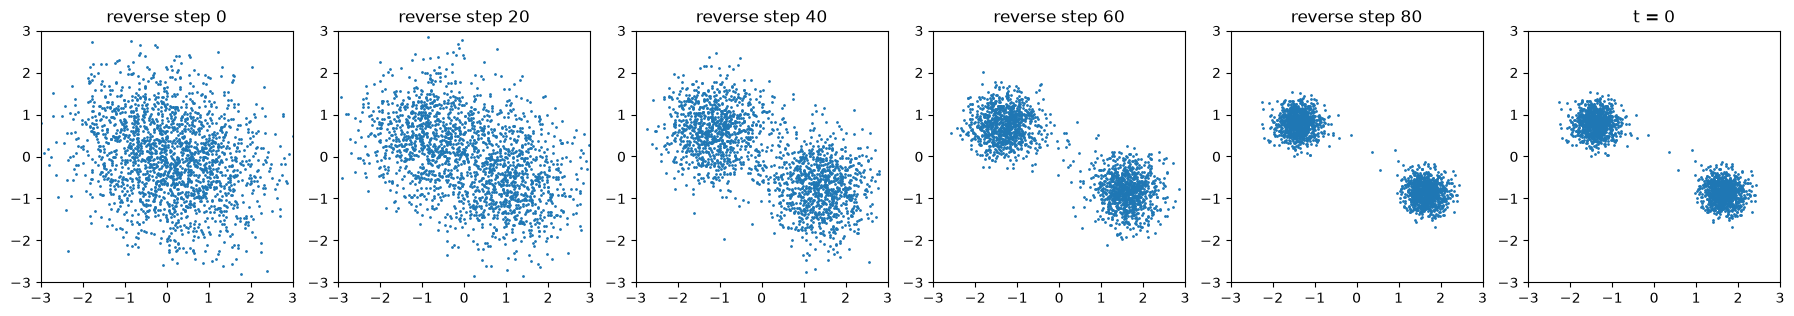

In [3]:
x_real, _ = data(2000)
uncond, traj = ddpm_sample(model, 2000, torch.full((2000,), 2), keep=True)
fig, axes = plt.subplots(1, len(traj) + 1, figsize=(3 * (len(traj) + 1), 3))
for ax, x, k in zip(axes, traj + [uncond], range(len(traj) + 1)):
    ax.scatter(*x.T, s=1); ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal"); ax.set_title(f"reverse step {k * 20}" if k < len(traj) else "t = 0")
plt.tight_layout(); plt.show()

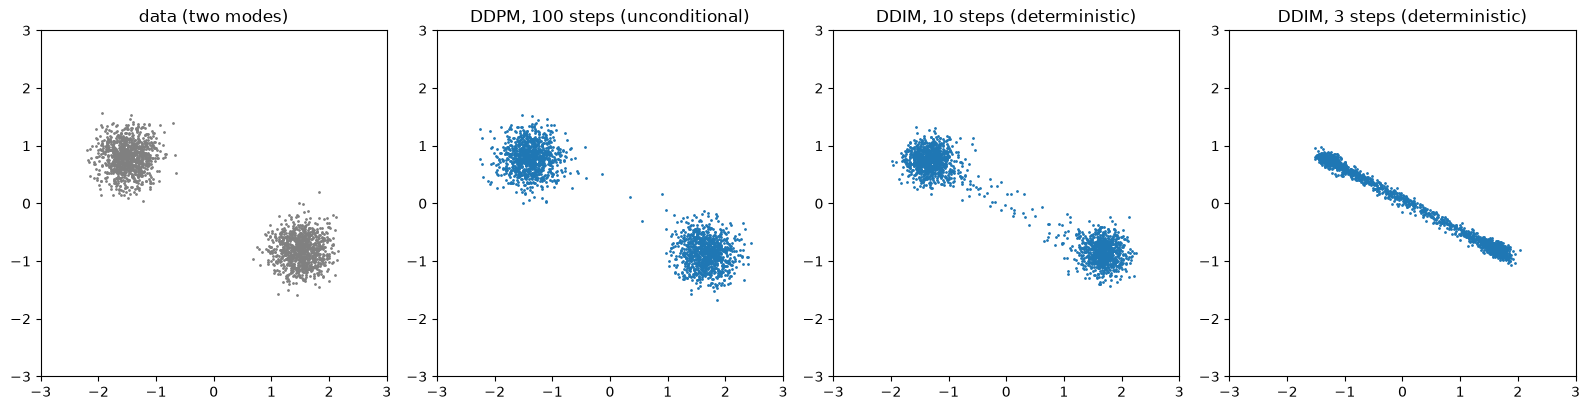

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].scatter(*x_real.T, s=1, c="gray"); axes[0].set_title("data (two modes)")
axes[1].scatter(*uncond.T, s=1); axes[1].set_title("DDPM, 100 steps (unconditional)")
for ax, steps in zip(axes[2:], [10, 3]):
    x = ddim_sample(model, 2000, torch.full((2000,), 2), steps)
    ax.scatter(*x.T, s=1); ax.set_title(f"DDIM, {steps} steps (deterministic)")
for ax in axes:
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

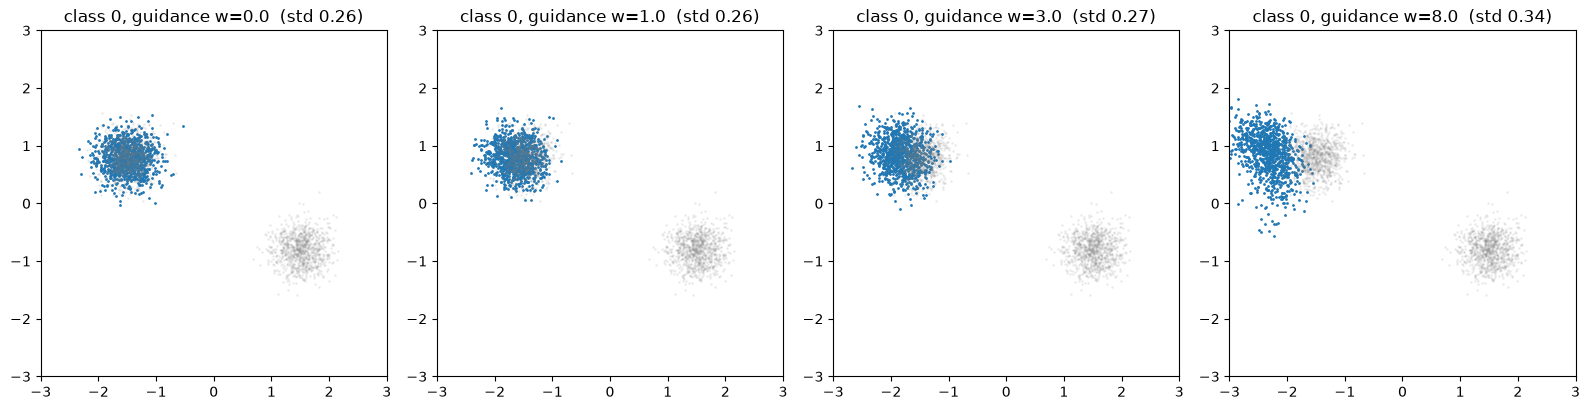

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, w in zip(axes, [0.0, 1.0, 3.0, 8.0]):
    x = ddpm_sample(model, 1000, torch.zeros(1000, dtype=torch.long), w=w)
    ax.scatter(*x.T, s=1); ax.scatter(*x_real.T, s=1, c="gray", alpha=0.1)
    ax.set_title(f"class 0, guidance w={w}  (std {x.std(0).mean():.2f})"); ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
plt.tight_layout(); plt.show()